In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, cohen_kappa_score, confusion_matrix, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = r"https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML241EN-SkillsNetwork/labs/datasets/Wine_Quality_Data.csv"
df = pd.read_csv(url)
df.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Analisis EDA

In [3]:
df.quality.unique()

array([5, 6, 7, 4, 8, 3, 9])

In [4]:
df.shape

(6497, 13)

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  color                 6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB
alcohol                 0.444319
citric_acid             0.085532
free_sulfur_

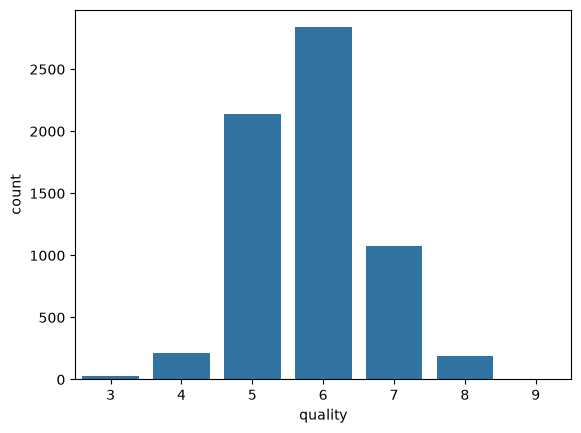

In [5]:
df.info()
df.describe()
df.quality.value_counts().sort_index()
df.color.value_counts()

#Correlacion con Quality
corr = df.select_dtypes(include=[np.number]).corr()['quality'].drop('quality').sort_values(ascending=False)
print(corr)

# Visualizar distribución de la variable objetivo

sns.countplot(x='quality', data=df)
plt.show()

Paso 3: Definir el objetivo (target)

In [6]:
df['good_wine'] = (df["quality"] >= 6).astype(int)
df = df.drop(columns=["quality"])

# Convertir 'color' en variable numérica
df["color"] = df["color"].replace({"red": 1, "white": 0})

print(df['good_wine'].value_counts(normalize=True))

good_wine
1    0.633061
0    0.366939
Name: proportion, dtype: float64


Paso 4: Separar features y target, train/test split

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
target = 'good_wine'

X = df.drop(columns= [target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42,stratify=y)

Paso 5: Escalado de variables

In [9]:
from sklearn.preprocessing import StandardScaler

In [10]:
scaler = StandardScaler()

#Estandariza con scaler los datos de entretamiento y prueba X 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Paso 6: Entrenar múltiples modelos (comparación de "herramientas")

In [11]:
models = {
    "Regresión Logística": LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    "Árbol de Decisión": DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=42),
    "SVM": SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_proba),
        "Kappa": cohen_kappa_score(y_test, y_pred),
    }

results_df = pd.DataFrame(results).T.sort_values("F1", ascending=False)
print(results_df.round(3))

c:\Users\kevin\Python\Machine Learning\Coursera\Modelos\env\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


                     Accuracy  Precision  Recall     F1    AUC  Kappa
Random Forest           0.842      0.878   0.871  0.874  0.906  0.660
Gradient Boosting       0.785      0.806   0.869  0.836  0.858  0.523
KNN                     0.756      0.784   0.848  0.815  0.811  0.459
AdaBoost                0.755      0.784   0.846  0.814  0.819  0.456
SVM                     0.766      0.853   0.762  0.805  0.844  0.515
Árbol de Decisión       0.742      0.848   0.723  0.780  0.813  0.473
Regresión Logística     0.728      0.825   0.724  0.772  0.806  0.440


Paso 7: Visualizar la comparación

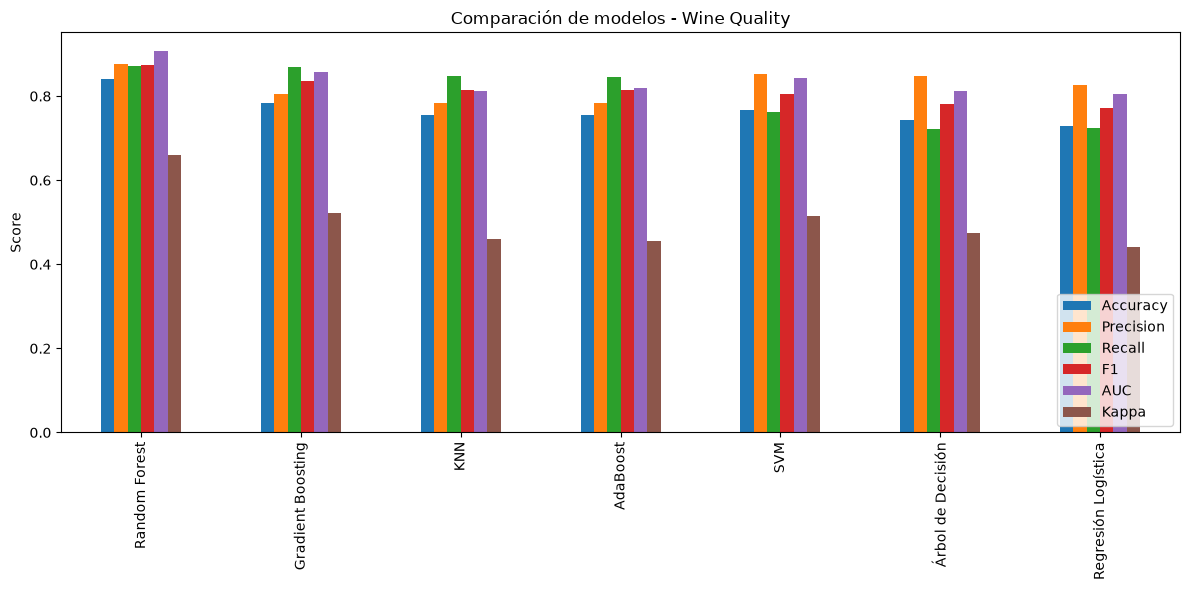

In [12]:
results_df.plot(kind='bar', figsize=(12,6))
plt.title("Comparación de modelos - Wine Quality")
plt.ylabel("Score")
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

Paso 8: Matriz de confusión del mejor modelo

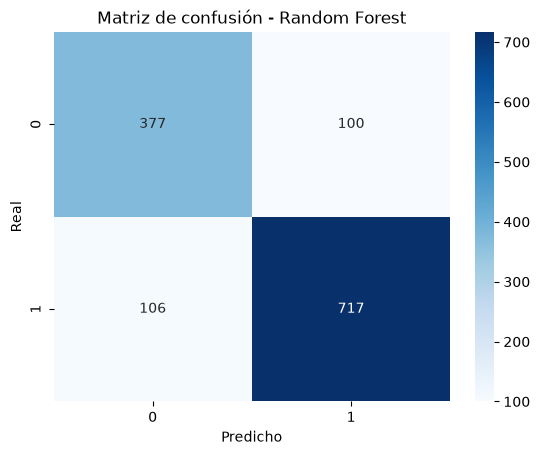

              precision    recall  f1-score   support

           0       0.78      0.79      0.79       477
           1       0.88      0.87      0.87       823

    accuracy                           0.84      1300
   macro avg       0.83      0.83      0.83      1300
weighted avg       0.84      0.84      0.84      1300



In [13]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f"Matriz de confusión - {best_model_name}")
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()

print(classification_report(y_test, y_pred_best))

Paso 9: Validación cruzada (robustez del resultado)

In [14]:
scores = cross_val_score(best_model, X_train_scaled, y_train, cv=5, scoring='f1')
print(f"F1 promedio (CV): {scores.mean():.3f} +/- {scores.std():.3f}")

F1 promedio (CV): 0.852 +/- 0.007


Paso 10: Ajuste de hiperparámetros (opcional, para el mejor modelo)

In [15]:
param_grid = {
    'n_estimators': [200, 300, 400],
    'max_depth': [4, 6, 8, None],
}
grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=42),
                     param_grid, scoring='f1', cv=5, n_jobs=-1)
grid.fit(X_train_scaled, y_train)
print(grid.best_params_, grid.best_score_)

{'max_depth': None, 'n_estimators': 400} 0.8535765584690665


Paso 11: Interpretar el modelo (importancia de variables)

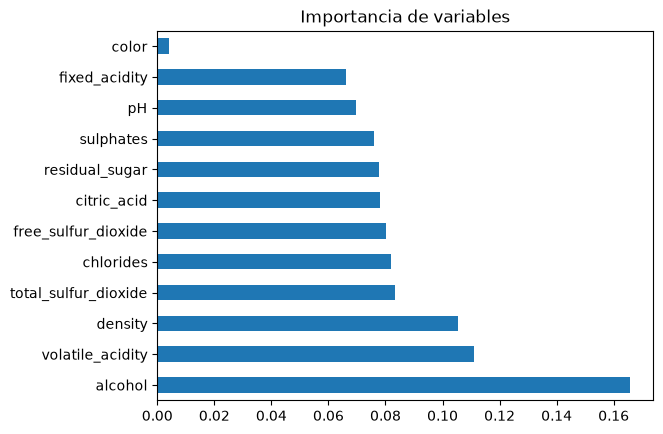

In [16]:
if hasattr(best_model, 'feature_importances_'):
    importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
    importances.plot(kind='barh')
    plt.title("Importancia de variables")
    plt.show()

Paso 12: Predicción con nuevos datos

In [17]:
# --- Ingresar los valores de un nuevo vino a clasificar ---
nuevo_vino = {
    "fixed_acidity": 7.4,
    "volatile_acidity": 0.35,
    "citric_acid": 0.30,
    "residual_sugar": 2.0,
    "chlorides": 0.065,
    "free_sulfur_dioxide": 15.0,
    "total_sulfur_dioxide": 40.0,
    "density": 0.9965,
    "pH": 3.30,
    "sulphates": 0.62,
    "alcohol": 11.5,
    "color": 1,   # 1 = red, 0 = white
}

# Convertir a DataFrame respetando el mismo orden de columnas que X
nuevo_df = pd.DataFrame([nuevo_vino])[X.columns]

# Escalar con el mismo scaler entrenado (NUNCA usar fit_transform aquí)
nuevo_scaled = scaler.transform(nuevo_df)

# Predicción
prediccion = best_model.predict(nuevo_scaled)[0]
probabilidad = best_model.predict_proba(nuevo_scaled)[0, 1]

resultado = "BUENO ✅" if prediccion == 1 else "NO BUENO ❌"
print(f"Predicción: {resultado}")
print(f"Probabilidad de ser 'bueno': {probabilidad:.2%}")

Predicción: BUENO ✅
Probabilidad de ser 'bueno': 85.33%
